In [5]:
from pathlib import Path
import pandas as pd

root = Path.cwd()
while not (root / "estaciones.csv").exists() and root != root.parent:
    root = root.parent

print("Carpeta raíz detectada:", root)

# Probamos con latin1 (si diera algún carácter raro, prueba con "cp1252")
estaciones = pd.read_csv(root / "estaciones.csv", encoding="latin1")
print("Estaciones:", estaciones.shape)
display(estaciones.head(3))

diarios_files = list(
    (root / "datos_historicos_csv" / "datos_diarios").glob("*.csv")
)
horarios_files = list(
    (root / "datos_historicos_csv" / "datos_horarios").glob("*.csv")
)

print("CSV en datos_diarios:", [f.name for f in diarios_files])
print("CSV en datos_horarios:", [f.name for f in horarios_files])


Carpeta raíz detectada: /Users/ordenadorhouse/Documents/GitHub/Gabriel-Acosta-DSOnline
Estaciones: (62, 1)


,,,,,Name;Description;Province;Town;Address;Coordenates X (ETRS89);Coordenates Y (ETRS89);Latitude;Longitude
ABANTO;;Bizkaia;Abanto y Ciérvana-Abanto Zierbena;Avda. del Minero,2. Ayuntamiento;493987,175;4796406,558;43,32047399433485;-3,7.415600e+14
AGURAIN;;Araba/Álava;Agurain/Salvatierra;C/ Fueros,11. Subcomisaría de la Ertzaintza.;549539,1393;4744226,3688;42,84901250588428;-2,3.937034e+15
"ALGORTA (BBIZI2);;Bizkaia;Getxo;""Carretera de Galea","s/n "";498154;4801022;43",362055748944286;-3,0227822073211765,nan,NaN


CSV en datos_diarios: ['PUYO.csv', 'SANGRONIZ.csv', 'ALGORTA_BBIZI2.csv', 'PAGOETA.csv', 'MONDRAGON.csv', 'LEZO.csv', 'ZELAIETA_PARQUE.csv', 'SESTAO.csv', 'BEASAIN.csv', 'CASTREJANA.csv', 'FARMACIA.csv', 'SANTURCE.csv', 'AVDA_TOLOSA.csv', 'ELCIEGO.csv', 'LEMONA.csv', 'TOLOSA.csv', 'AV_GASTEIZ.csv', 'ERANDIO.csv', 'MUSKIZ.csv', 'HERNANI.csv', 'BASAURI.csv', 'LASARTE-ORIA.csv', 'EASO.csv', 'MUNDAKA.csv', 'ZALLA.csv', 'UNIDAD_MOVIL_2.csv', 'ANDOAIN.csv', 'DURANGO.csv', 'MONTORRA.csv', 'LLODIO.csv', 'SAN_JULIAN.csv', 'LOS_HERRAN.csv', 'ARRAIZ_Monte.csv', 'LARRABETZU.csv', 'AZPEITIA.csv', 'M_DIAZ_HARO.csv', 'EUROPA.csv', 'ZUMARRAGA.csv', '3_DE_MARZO.csv', 'SAN_MIGUEL.csv', 'BARAKALDO.csv', 'SERANTES.csv', 'ALONSOTEGI.csv', 'USURBIL.csv', 'MAZARREDO.csv', 'AGURAIN.csv', 'UNIDAD_MOVIL_10.csv', 'ZUBIETA.csv', 'LAS_CARRERAS.csv', 'ABANTO.csv', 'ZIERBENA_Puerto.csv', 'MUNOA.csv', 'ANORGA.csv', 'VALDEREJO.csv', 'URKIOLA.csv', 'JAIZKIBEL.csv', 'ATEGORRIETA.csv']
CSV en datos_horarios: ['PUYO.csv',

In [6]:
# 1. Recargar estaciones separando por punto y coma
estaciones = pd.read_csv(root / "estaciones.csv", encoding="latin1", sep=";")
print("Estaciones limpias:", estaciones.shape)
print("Columnas estaciones:", list(estaciones.columns))
display(estaciones.head(5))

# 2. Tomar el primer CSV de datos_diarios como prueba
sample_path = diarios_files[0]
print("Probando archivo:", sample_path.name)

# Probamos lectura estándar; si sale en 1 columna, le pondremos sep=";"
med_sample = pd.read_csv(sample_path, encoding="latin1")
if med_sample.shape[1] == 1:
    med_sample = pd.read_csv(sample_path, encoding="latin1", sep=";")

print("Dimensiones muestra:", med_sample.shape)
print("Columnas mediciones:", list(med_sample.columns))
display(med_sample.head(5))


Estaciones limpias: (62, 9)
Columnas estaciones: ['Name', 'Description', 'Province', 'Town', 'Address', 'Coordenates X (ETRS89)', 'Coordenates Y (ETRS89)', 'Latitude', 'Longitude']


,Name,Description,Province,Town,Address,Coordenates X (ETRS89),Coordenates Y (ETRS89),Latitude,Longitude
0,ABANTO,NaN,Bizkaia,Abanto y Ciérvana-Abanto Zierbena,"Avda. del Minero, 2. Ayuntamiento","493987,175","4796406,558","43,32047399433485","-3,0741559961978044"
1,AGURAIN,NaN,Araba/Álava,Agurain/Salvatierra,"C/ Fueros, 11. Subcomisaría de la Ertzaintza.","549539,1393","4744226,3688","42,84901250588428","-2,3937033896081683"
2,ALGORTA (BBIZI2),NaN,Bizkaia,Getxo,"Carretera de Galea, s/n",498154,4801022,"43,362055748944286","-3,0227822073211765"
3,ALONSOTEGI,NaN,Bizkaia,Alonsotegi,"C/ Baztieta, s/n. Bº Irauregi","500972,2158","4788307,4677","43,247567997964374","-2,988024000380936"
4,ANDOAIN,NaN,Gipuzkoa,Andoain,Ikastola Aita larramendi,579321,4785862,"43,22137866586519","-2,02332524753123"


Probando archivo: PUYO.csv
Dimensiones muestra: (326, 2)
Columnas mediciones: ['Date;NO (µg/m3);NOX (µg/m3);NO2 (µg/m3);O3 (µg/m3);O3 8h (µg/m3);PM10 (µg/m3);PM2', '5 (µg/m3);SO2 (µg/m3)']


,Date;NO (µg/m3);NOX (µg/m3);NO2 (µg/m3);O3 (µg/m3);O3 8h (µg/m3);PM10 (µg/m3);PM2,5 (µg/m3);SO2 (µg/m3)
0,22/11/2026;0;5;5;60;61;9;4;4,NaN
1,21/11/2026;0;7;7;53;48;4;1;4,NaN
2,20/11/2026;1;18;16;40;41;12;4;4,NaN
3,19/11/2026;1;11;11;53;55;14;5;4,NaN
4,18/11/2026;1;10;9;55;55;13;6;4,NaN


In [7]:
dfs_diarios = []

for path in diarios_files:
    df_tmp = pd.read_csv(path, encoding="latin1", sep=";")
    # Guardamos el identificador del archivo (ej. PUYO, SANGRONIZ, etc.)
    df_tmp["archivo_estacion"] = path.stem
    dfs_diarios.append(df_tmp)

med_diarias = pd.concat(dfs_diarios, ignore_index=True)

print("Total filas mediciones diarias:", med_diarias.shape)
print("Columnas:", list(med_diarias.columns))
display(med_diarias.head(5))


Total filas mediciones diarias: (18489, 19)
Columnas: ['Date', 'NO (µg/m3)', 'NOX (µg/m3)', 'NO2 (µg/m3)', 'O3 (µg/m3)', 'O3 8h (µg/m3)', 'PM10 (µg/m3)', 'PM2,5 (µg/m3)', 'SO2 (µg/m3)', 'archivo_estacion', 'CO (mg/m3)', 'CO 8h (mg/m3)', 'Benceno (µg/m3)', 'Etilbenceno (µg/m3)', 'Ortoxileno (µg/m3)', 'Tolueno (µg/m3)', 'NH3 (µg/m3)', 'M-P-XILENO (µg/m3)', 'SH2 (µg/m3)']


,Date,NO (µg/m3),NOX (µg/m3),NO2 (µg/m3),O3 (µg/m3),O3 8h (µg/m3),PM10 (µg/m3),"PM2,5 (µg/m3)",SO2 (µg/m3),archivo_estacion,CO (mg/m3),CO 8h (mg/m3),Benceno (µg/m3),Etilbenceno (µg/m3),Ortoxileno (µg/m3),Tolueno (µg/m3),NH3 (µg/m3),M-P-XILENO (µg/m3),SH2 (µg/m3)
0,22/11/2026,0.0,5.0,5.0,60.0,61.0,9.0,4.0,4.0,PUYO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,21/11/2026,0.0,7.0,7.0,53.0,48.0,4.0,1.0,4.0,PUYO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,20/11/2026,1.0,18.0,16.0,40.0,41.0,12.0,4.0,4.0,PUYO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,19/11/2026,1.0,11.0,11.0,53.0,55.0,14.0,5.0,4.0,PUYO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,18/11/2026,1.0,10.0,9.0,55.0,55.0,13.0,6.0,4.0,PUYO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
import numpy as np
import pandas as pd

# 1. Convertir Date a formato fecha real y sacar mes / día de la semana
med_diarias["fecha"] = pd.to_datetime(
    med_diarias["Date"], format="%d/%m/%Y", errors="coerce"
)
med_diarias["mes"] = med_diarias["fecha"].dt.month
med_diarias["dia_semana"] = med_diarias["fecha"].dt.day_name()

# 2. Asegurar columnas numéricas (por si alguna vino como texto o con coma decimal)
cols_excluir = {"Date", "archivo_estacion", "fecha", "mes", "dia_semana"}
for col in med_diarias.columns:
  if col not in cols_excluir:
    if med_diarias[col].dtype == "object":
      med_diarias[col] = med_diarias[col].astype(str).str.replace(",", ".")
    med_diarias[col] = pd.to_numeric(med_diarias[col], errors="coerce")

# 3. Revisar porcentaje de nulos por columna (clave para el EDA)
print("Porcentaje de nulos por columna:")
display(
    (med_diarias.isna().mean() * 100)
    .round(1)
    .sort_values(ascending=False)
    .to_frame("%_nulos")
)

# 4. Normalizar clave para cruzar con estaciones (ej. quitar espacios/guiones bajos/paréntesis)
estaciones["clave_match"] = (
    estaciones["Name"]
    .astype(str)
    .str.upper()
    .str.replace(r"[^A-Z0-9]", "", regex=True)
)
med_diarias["clave_match"] = (
    med_diarias["archivo_estacion"]
    .astype(str)
    .str.upper()
    .str.replace(r"[^A-Z0-9]", "", regex=True)
)

df_eda = med_diarias.merge(
    estaciones[["clave_match", "Name", "Province", "Town"]],
    on="clave_match",
    how="left",
)

print("Filas sin cruce con estaciones:", df_eda["Province"].isna().sum())
display(
    df_eda[[
        "fecha",
        "archivo_estacion",
        "Name",
        "Province",
        "Town",
        "NO2 (µg/m3)",
        "PM10 (µg/m3)",
    ]].head(5)
)


Porcentaje de nulos por columna:


,%_nulos
CO 8h (mg/m3),100.0
CO (mg/m3),100.0
M-P-XILENO (µg/m3),99.8
Tolueno (µg/m3),99.8
Ortoxileno (µg/m3),99.8
Benceno (µg/m3),99.8
Etilbenceno (µg/m3),98.9
NH3 (µg/m3),96.5
SH2 (µg/m3),90.3
O3 8h (µg/m3),54.2


Filas sin cruce con estaciones: 978


,fecha,archivo_estacion,Name,Province,Town,NO2 (µg/m3),PM10 (µg/m3)
0,2026-11-22,PUYO,PUYO,Gipuzkoa,Donostia / San Sebastián,5.0,9.0
1,2026-11-21,PUYO,PUYO,Gipuzkoa,Donostia / San Sebastián,7.0,4.0
2,2026-11-20,PUYO,PUYO,Gipuzkoa,Donostia / San Sebastián,16.0,12.0
3,2026-11-19,PUYO,PUYO,Gipuzkoa,Donostia / San Sebastián,11.0,14.0
4,2026-11-18,PUYO,PUYO,Gipuzkoa,Donostia / San Sebastián,9.0,13.0


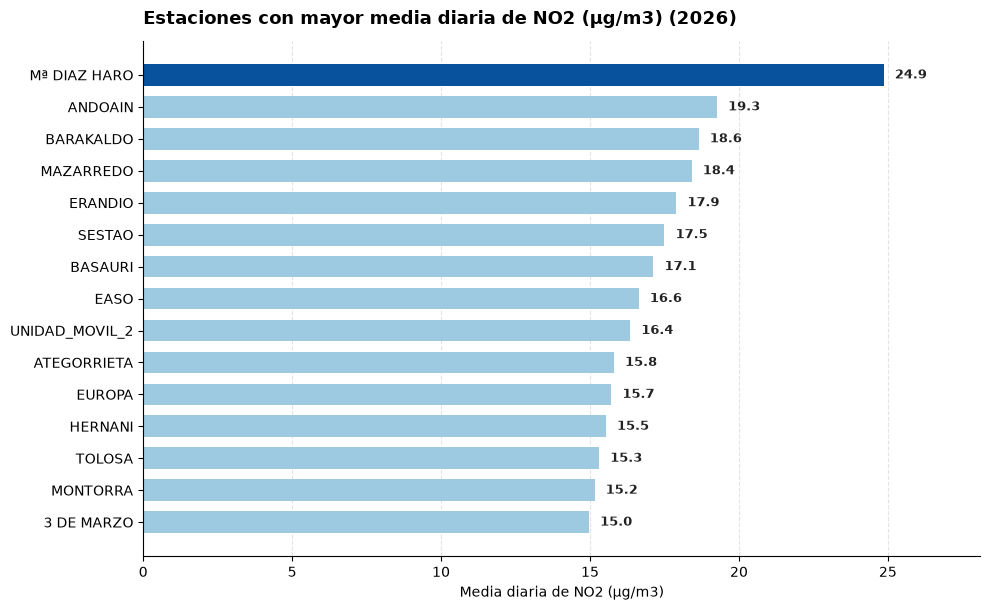

In [13]:
import matplotlib.pyplot as plt

contaminante = "NO2 (µg/m3)"
etiqueta_estacion = df_eda["Name"].fillna(df_eda["archivo_estacion"])

ranking = (
    df_eda.assign(estacion_label=etiqueta_estacion)
    .groupby("estacion_label", as_index=False)[contaminante]
    .agg(media="mean", conteo="count")
    .query("conteo >= 10")
    .sort_values("media", ascending=False)
    .head(15)
)

# De mayor a menor de arriba abajo
ranking_plot = ranking.iloc[::-1].reset_index(drop=True)

# Color destacado para la barra más alta (la última tras invertir)
colores = ["#9ecae1"] * (len(ranking_plot) - 1) + ["#08519c"]

fig, ax = plt.subplots(figsize=(10, 6.2))
barras = ax.barh(
    ranking_plot["estacion_label"],
    ranking_plot["media"],
    color=colores,
    height=0.68,
)

# Etiqueta con el valor al lado de cada barra
for barra in barras:
  ancho = barra.get_width()
  ax.text(
      ancho + ranking_plot["media"].max() * 0.015,
      barra.get_y() + barra.get_height() / 2,
      f"{ancho:.1f}",
      va="center",
      ha="left",
      fontsize=9.5,
      fontweight="bold",
      color="#222222",
  )

ax.set_xlim(0, ranking_plot["media"].max() * 1.13)
ax.set_title(
    f"Estaciones con mayor media diaria de {contaminante} (2026)",
    fontsize=13,
    fontweight="bold",
    loc="left",
    pad=12,
)
ax.set_xlabel(f"Media diaria de {contaminante}", fontsize=10)
ax.set_ylabel("")
ax.xaxis.grid(True, linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

# Quitar bordes superior y derecho
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


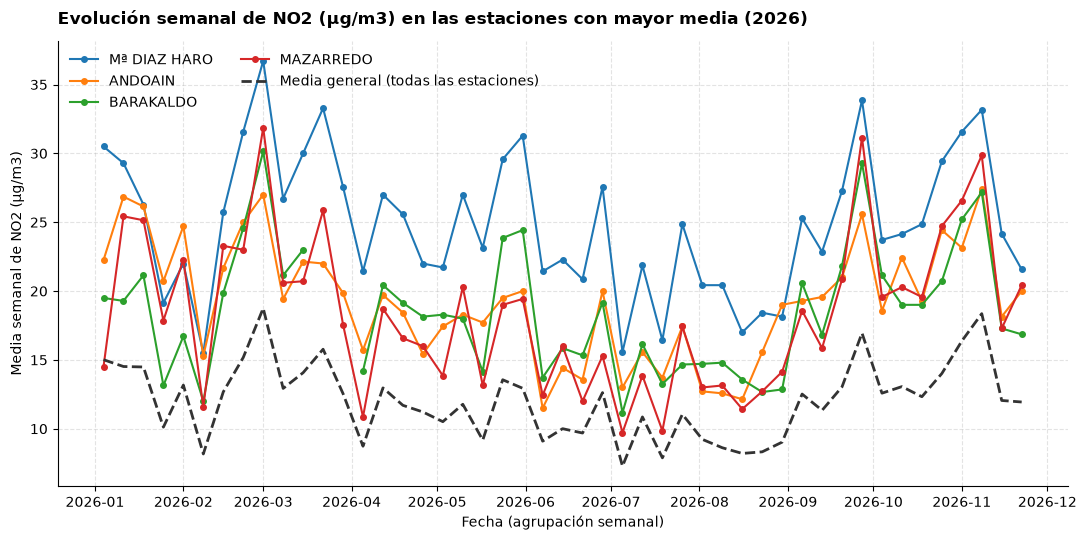

In [14]:
import matplotlib.pyplot as plt

contaminante = "NO2 (µg/m3)"
df_plot = df_eda.dropna(subset=["fecha", contaminante]).copy()
df_plot["estacion_label"] = df_plot["Name"].fillna(df_plot["archivo_estacion"])

# Tomamos las top 4 estaciones del ranking actual para no saturar el gráfico
top_estaciones = (
    df_plot.groupby("estacion_label")[contaminante]
    .mean()
    .sort_values(ascending=False)
    .head(4)
    .index.tolist()
)

# Media semanal por estación
df_sem = (
    df_plot[df_plot["estacion_label"].isin(top_estaciones)]
    .set_index("fecha")
    .groupby("estacion_label")[contaminante]
    .resample("W")
    .mean()
    .reset_index()
)

# Media semanal general de todas las estaciones como referencia
media_general_sem = (
    df_plot.set_index("fecha")[contaminante].resample("W").mean().reset_index()
)

fig, ax = plt.subplots(figsize=(11, 5.5))

for est in top_estaciones:
  sub = df_sem[df_sem["estacion_label"] == est]
  ax.plot(
      sub["fecha"], sub[contaminante], marker="o", markersize=4, label=est
  )

ax.plot(
    media_general_sem["fecha"],
    media_general_sem[contaminante],
    color="#333333",
    linestyle="--",
    linewidth=2,
    label="Media general (todas las estaciones)",
)

ax.set_title(
    f"Evolución semanal de {contaminante} en las estaciones con mayor media"
    " (2026)",
    fontsize=12.5,
    fontweight="bold",
    loc="left",
    pad=12,
)
ax.set_xlabel("Fecha (agrupación semanal)")
ax.set_ylabel(f"Media semanal de {contaminante}")
ax.grid(True, linestyle="--", alpha=0.35)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False, loc="upper left", ncol=2)

plt.tight_layout()
plt.show()


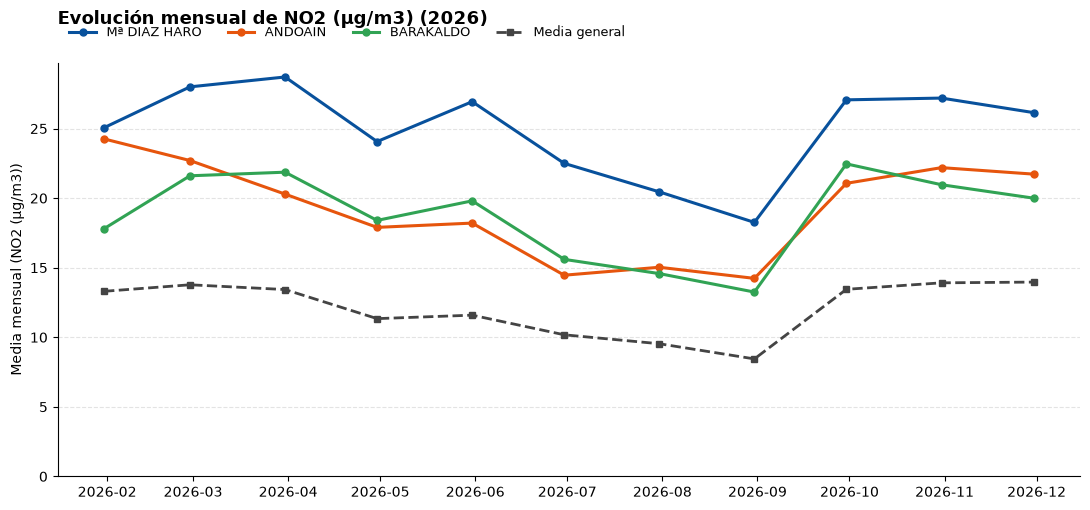

In [15]:
import matplotlib.pyplot as plt

contaminante = "NO2 (µg/m3)"
df_plot = df_eda.dropna(subset=["fecha", contaminante]).copy()
df_plot["estacion_label"] = df_plot["Name"].fillna(df_plot["archivo_estacion"])

# Top 3 estaciones para reducir el cruce de líneas
top_estaciones = (
    df_plot.groupby("estacion_label")[contaminante]
    .mean()
    .sort_values(ascending=False)
    .head(3)
    .index.tolist()
)

# Agrupación mensual ('ME' = fin de mes) para una curva mucho más limpia
df_mes = (
    df_plot[df_plot["estacion_label"].isin(top_estaciones)]
    .set_index("fecha")
    .groupby("estacion_label")[contaminante]
    .resample("ME")
    .mean()
    .reset_index()
)

media_general_mes = (
    df_plot.set_index("fecha")[contaminante].resample("ME").mean().reset_index()
)

fig, ax = plt.subplots(figsize=(11, 5.2))

paleta = ["#08519c", "#e6550d", "#31a354"]

for est, color in zip(top_estaciones, paleta):
  sub = df_mes[df_mes["estacion_label"] == est]
  ax.plot(
      sub["fecha"],
      sub[contaminante],
      color=color,
      linewidth=2.2,
      marker="o",
      markersize=5,
      label=est,
  )

ax.plot(
    media_general_mes["fecha"],
    media_general_mes[contaminante],
    color="#444444",
    linestyle="--",
    linewidth=2,
    marker="s",
    markersize=4.5,
    label="Media general",
)

ax.set_title(
    f"Evolución mensual de {contaminante} (2026)",
    fontsize=13,
    fontweight="bold",
    loc="left",
    pad=28,
)
ax.set_ylabel(f"Media mensual ({contaminante})")
ax.set_xlabel("")
ax.set_ylim(bottom=0)
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Leyenda limpia arriba, fuera del trazado
ax.legend(
    frameon=False,
    loc="upper left",
    bbox_to_anchor=(0, 1.12),
    ncol=4,
    fontsize=9.5,
)

plt.tight_layout()
plt.show()


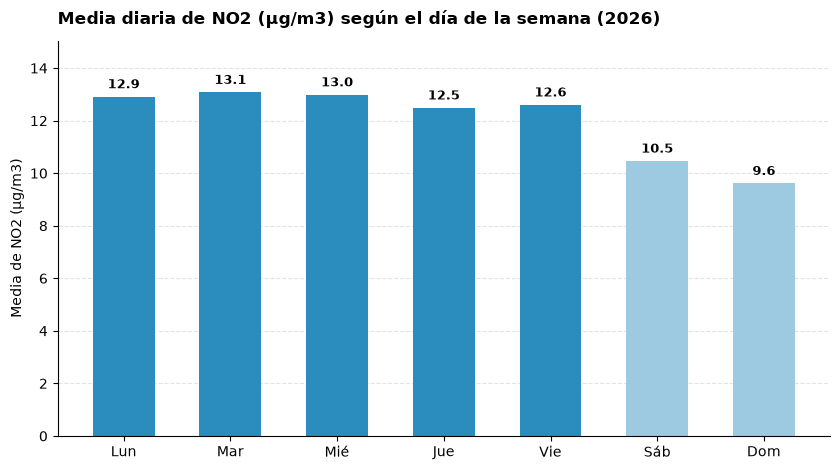

In [16]:
import matplotlib.pyplot as plt

contaminante = "NO2 (µg/m3)"
df_dia = df_eda.dropna(subset=["fecha", contaminante]).copy()

# Orden cronológico de lunes a domingo (mapeamos inglés -> español para que se lea claro)
mapa_dias = {
    "Monday": "Lun",
    "Tuesday": "Mar",
    "Wednesday": "Mié",
    "Thursday": "Jue",
    "Friday": "Vie",
    "Saturday": "Sáb",
    "Sunday": "Dom",
}
orden_dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]

df_dia["dia_es"] = df_dia["dia_semana"].map(mapa_dias)

prom_dia = (
    df_dia.groupby("dia_es", as_index=False)[contaminante]
    .mean()
    .set_index("dia_es")
    .reindex(orden_dias)
    .reset_index()
)

# Resaltamos fin de semana en otro tono para que contraste
colores_dia = [
    "#2b8cbe",
    "#2b8cbe",
    "#2b8cbe",
    "#2b8cbe",
    "#2b8cbe",
    "#9ecae1",
    "#9ecae1",
]

fig, ax = plt.subplots(figsize=(8.5, 4.8))
barras = ax.bar(
    prom_dia["dia_es"], prom_dia[contaminante], color=colores_dia, width=0.58
)

for barra in barras:
  alto = barra.get_height()
  ax.text(
      barra.get_x() + barra.get_width() / 2,
      alto + prom_dia[contaminante].max() * 0.015,
      f"{alto:.1f}",
      ha="center",
      va="bottom",
      fontsize=9.5,
      fontweight="bold",
  )

ax.set_title(
    f"Media diaria de {contaminante} según el día de la semana (2026)",
    fontsize=12.5,
    fontweight="bold",
    loc="left",
    pad=12,
)
ax.set_ylabel(f"Media de {contaminante}")
ax.set_ylim(0, prom_dia[contaminante].max() * 1.15)
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


## Conclusiones preliminares del EDA — Calidad del aire en Euskadi (2026)

### 1. Calidad y cobertura de los datos
* **Disponibilidad por contaminante:** En los registros diarios (`18.489` filas consolidadas), los compuestos con mejor cobertura son **NOX** (`12,8 %` de nulos), **NO2** (`14,5 %`), **NO** (`15,9 %`) y **PM10** (`17,2 %`). Por el contrario, **CO** y **CO 8h** presentan un `100 %` de valores nulos y compuestos orgánicos como **Benceno**, **Tolueno** o **Xilenos** superan el `98 %` de nulos, por lo que no son adecuados para un análisis general sin filtrar estaciones específicas.
* **Cruce con el catálogo de estaciones:** Al normalizar nombres e integrar las mediciones diarias con `estaciones.csv` (`62` estaciones), la gran mayoría de registros cruzan correctamente con provincia y municipio, quedando `978` filas sin correspondencia directa (estaciones o unidades móviles con nomenclatura distinta en el archivo diario).

---

### 2. Hallazgos principales sobre el Dióxido de Nitrógeno ($\text{NO}_2$)
* **Diferencias entre estaciones:** **Mª DIAZ HARO** lidera con claridad la media diaria con **24,9 µg/m³**, seguida de **ANDOAIN** (**19,3 µg/m³**), **BARAKALDO** (**18,6 µg/m³**), **MAZARREDO** (**18,4 µg/m³**) y **ERANDIO** (**17,9 µg/m³**), todas ellas situadas en entornos urbanos o corredores de tráfico intenso.
* **Estacionalidad anual:** La evolución mensual muestra un descenso sostenido durante los meses de verano (**julio a septiembre**), alcanzando su mínimo en **septiembre**, y un repunte marcado a partir de **octubre**, manteniendo las estaciones principales siempre por encima de la media general de Euskadi.
* **Patrón semanal (efecto tráfico/actividad):** De **lunes a viernes** la concentración media diaria se mantiene estable entre **12,5 y 13,1 µg/m³**, mientras que en **fin de semana** desciende de forma clara hasta **10,5 µg/m³** el sábado y **9,6 µg/m³** el domingo (una caída de alrededor del `20-25 %` respecto a los días laborables).

---

### 3. Próximos pasos (pendiente de requerimientos finales)
* Revisar y mapear manualmente los nombres de las estaciones que quedaron sin cruce (`978` filas) para completar su información geográfica (`Province`, `Town`).
* Ampliar la comparativa a otros contaminantes con buena cobertura (**PM10**, **O3**) y analizar diferencias por **provincia** o **municipio**.
* Incorporar los datos horarios (`datos_horarios`) si se requiere analizar picos por franja horaria (horas punta de mañana y tarde).
